In [ ]:
print("Plant Disease Detection Project Started!")

Plant Disease Detection Project Started!


In [ ]:
!pip install -q gradio transformers torch pillow

In [ ]:
from transformers import pipeline

model = pipeline(
    "image-classification",
    model="neghani/plantvillage-mobilenetv2",
    revision="v1.0"
)

print("AI model loaded successfully!")

config.json:   0%|          | 0.00/3.53k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 9.26MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

AI model loaded successfully!


Saving leaf.jpeg to leaf.jpeg


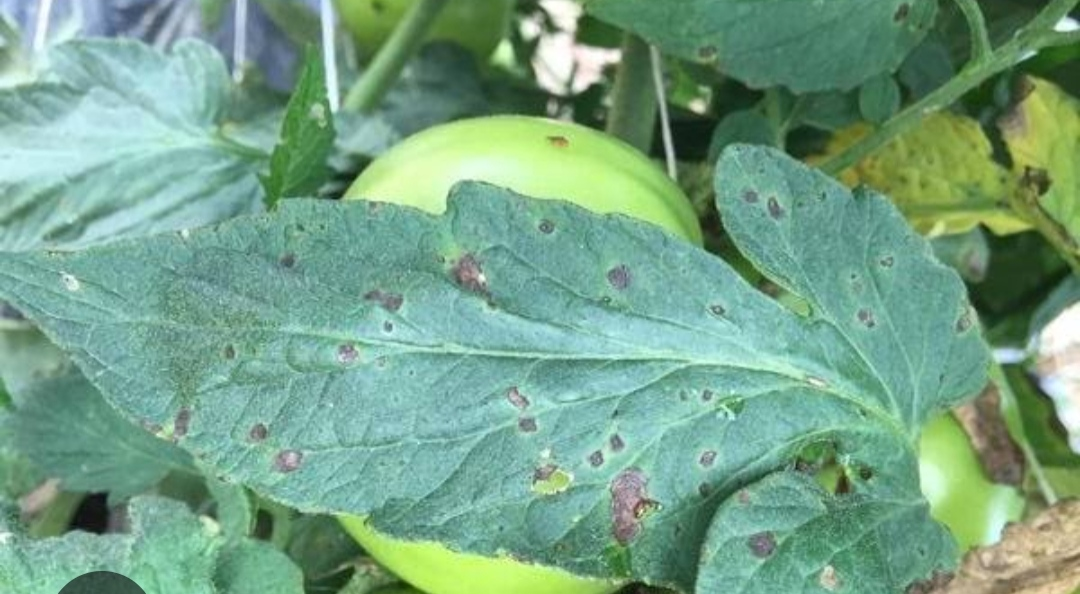

Tomato___Early_blight 95.03 %
Tomato___Septoria_leaf_spot 1.83 %
Grape___Black_rot 1.1 %


In [ ]:
from PIL import Image
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")

display(image)

results = model(image, top_k=3)

for result in results:
    print(
        result["label"],
        round(result["score"] * 100, 2),
        "%"
    )

In [ ]:
import gradio as gr

# Disease prediction function
def predict_disease(image):

    if image is None:
        return "Please upload a plant leaf image."

    # AI model prediction
    results = model(
        image.convert("RGB"),
        top_k=3
    )

    # Best prediction
    best = results[0]

    disease = best["label"].replace(
        "___", " - "
    ).replace("_", " ")

    confidence = round(
        best["score"] * 100, 2
    )

    # Show top 3 predictions
    output = "🌿 PLANT DISEASE DETECTION RESULT\n\n"

    output += f"Predicted Disease: {disease}\n"

    output += f"Confidence: {confidence}%\n\n"

    output += "Other Predictions:\n"

    for result in results:
        name = result["label"].replace(
            "___", " - "
        ).replace("_", " ")

        score = round(
            result["score"] * 100, 2
        )

        output += f"{name}: {score}%\n"

    return output
# Website Design - Professional Version

custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
    background: #f4f9f4;
}

#hero {
    background: linear-gradient(135deg, #14532d, #22c55e);
    color: white;
    padding: 35px;
    border-radius: 18px;
    text-align: center;
    margin-bottom: 20px;
}

#hero h1 {
    color: white;
    font-size: 36px;
}

#hero p {
    color: white;
    font-size: 17px;
}

.section-title {
    color: #166534;
    text-align: center;
}

#detect-btn {
    background: #15803d;
    color: white;
    font-weight: bold;
    border-radius: 10px;
}

#result-box textarea {
    font-size: 16px !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=custom_css,
    title="PlantCare AI | Plant Disease Detection"
) as demo:

    gr.Markdown("""
    <div id="hero">
        <h1>🌿 PlantCare AI</h1>
        <p>Plant Disease Detection Using Deep Learning</p>
        <p>Upload a leaf image and let Artificial Intelligence
        predict the possible plant disease.</p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("## 📸 Upload Plant Image")

            image = gr.Image(
                type="pil",
                label="Choose a plant leaf image"
            )

            button = gr.Button(
                "🔍 Detect Plant Disease",
                variant="primary",
                elem_id="detect-btn"
            )

            gr.Markdown("""
            **For better results:**
            - Upload a clear leaf image.
            - Keep the leaf in good lighting.
            - Avoid blurry photographs.
            """)

        with gr.Column(scale=1):
            gr.Markdown("## 🔬 AI Detection Result")

            result = gr.Textbox(
                label="Prediction and Confidence",
                lines=10,
                interactive=False,
                elem_id="result-box"
            )

            gr.Markdown("""
            ### 🌱 About the Result

            The AI model predicts the most likely disease
            based on the uploaded image.

            Always verify the result before deciding on
            any plant treatment.
            """)

    button.click(
        fn=predict_disease,
        inputs=image,
        outputs=result
    )

    gr.Markdown("""
    ---

    ## 🌍 About This Project

    This project uses Deep Learning and an image
    classification model to identify possible plant diseases.

    **Technologies:** Python · Gradio · PyTorch · Hugging Face

    **Applications:** Smart Agriculture · Plant Health Monitoring

    ---

    <div style="text-align:center">
        <p>🌿 PlantCare AI | Academic Project</p>
        <p>AI predictions are estimates and may not always be accurate.</p>
    </div>
    """)

demo.launch(share=True, debug=True)



/tmp/ipykernel_2269/926877687.py:92: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c705da61b5a9170ac5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
disease_info = {
    "Early blight": {
        "Symptoms": "Brown spots with circular rings on leaves.",
        "Prevention": "Remove infected leaves, avoid wetting foliage, and maintain good airflow."
    },
    "Late blight": {
        "Symptoms": "Dark, water-soaked patches on leaves.",
        "Prevention": "Remove infected plant material and avoid overhead watering."
    },
    "Healthy": {
        "Symptoms": "No obvious disease symptoms detected.",
        "Prevention": "Continue regular watering and monitor the plant."
    }
}

print("PlantCare AI disease information loaded successfully!")

PlantCare AI disease information loaded successfully!
